In [1]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, average_precision_score, confusion_matrix
import xgboost as xgb
import lightgbm as lgb
import warnings
import time
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

# Part 1: Algorithmic Benchmarking & Baseline Evaluation
---
**Objective:** 
Before committing to a complex, resource-heavy architecture, we must establish performance baselines. We will evaluate four distinct algorithms to determine if advanced gradient boosting frameworks are necessary, or if simpler, highly explainable models suffice.

**Model Selection Strategy:**
1. **Logistic Regression (Baseline Linear):** Fast and highly explainable. Serves as a baseline to test if the classes can be separated using linear decision boundaries.
2. **Random Forest (Baseline Ensemble):** A robust, non-linear bagging algorithm. Highly resistant to unscaled data and outliers. 
3. **XGBoost (Industry Standard Boosting):** A sequential tree-building algorithm that strictly penalizes minority class errors. The standard for tabular financial data.
4. **LightGBM (High-Efficiency Boosting):** Utilizes a histogram-based algorithm with leaf-wise tree growth. Serves as a faster, memory-efficient challenger to XGBoost.

*Note: Initial benchmarks will utilize the raw dataset (with only duplicates dropped) to test the algorithms' native robustness. Basic hyperparameters (`class_weight='balanced'` and `scale_pos_weight`) are applied to prevent the models from collapsing into majority-class predictors.*

In [2]:
#Load dataset
df=pd.read_csv("creditcard_benchmark.csv")

In [3]:
#Checking if dataset loaded
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
def get_models(y_train):
    scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()
    models = {
        "Logistic Regression": LogisticRegression(
            class_weight='balanced', 
            max_iter=1000, 
            random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=50, 
            class_weight='balanced', 
            n_jobs=-1, 
            random_state=42
        ),
        "XGBoost": xgb.XGBClassifier(
            scale_pos_weight=scale_pos_weight_value,
            n_jobs=-1, 
            random_state=42,
            eval_metric='logloss'
        ),
        "LightGBM": lgb.LGBMClassifier(
            class_weight='balanced',
            n_jobs=-1, 
            random_state=42
        )
    }
    return models

In [17]:
def run_benchmark(X_train, X_test, y_train, y_test):
    models = get_models(y_train)
    results = []
    for name, model in models.items():
        start_time = time.time()
        
        model.fit(X_train, y_train)
        
        train_time = time.time()-start_time
        
        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            y_pred_proba = model.predict_proba(X_test)[:,1]
        else:
            y_pred_proba = model.decision_function(X_test)

        f1 = f1_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        pr_auc = average_precision_score(y_test, y_pred_proba)
        cm = confusion_matrix(y_test, y_pred)

        print(f"Confusion matrix {name}")
        print(f"Class 0 - True negatives: {cm[0][0]:>6} | False positives: {cm[0][1]:>4}")
        print(f"Class 1 - False negatives: {cm[1][0]:>6} | True positives: {cm[1][1]:>4}\n")

        results.append({
        "Model": name,
        "F1-Score": round(f1, 4),
        "Recall": round(recall, 4),
        "Precision": round(precision, 4),
        "PR-AUC": round(pr_auc, 4),
        "Time [s]": round(train_time, 4)
        })

    results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending = False)
    return results_df
        

In [18]:
results = run_benchmark(X_train, X_test, y_train, y_test)
print("Benchmark results:")
display(results)

C:\Users\Radek\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Confusion matrix Logistic Regression
Class 0 - True negatives:  55193 | False positives: 1458
Class 1 - False negatives:     12 | True positives:   83

Confusion matrix Random Forest
Class 0 - True negatives:  56650 | False positives:    1
Class 1 - False negatives:     29 | True positives:   66

Confusion matrix XGBoost
Class 0 - True negatives:  56648 | False positives:    3
Class 1 - False negatives:     22 | True positives:   73

[LightGBM] [Info] Number of positive: 378, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005894 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 226980, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Confusion matrix LightGBM
Class 0 - True negatives:  56637 | False pos

,Model,F1-Score,Recall,Precision,PR-AUC,Time [s]
2,XGBoost,0.8538,0.7684,0.9605,0.8236,0.4350
3,LightGBM,0.8152,0.7895,0.8427,0.8065,0.4669
1,Random Forest,0.8148,0.6947,0.9851,0.7893,3.8512
0,Logistic Regression,0.1015,0.8737,0.0539,0.6514,8.4424


### Raw Data Benchmark Analysis

**Initial Insights:**
* **Precision Collapse in Linear Models:** As anticipated, Logistic Regression failed to converge effectively on the unscaled data. While it achieved the highest Recall (catching the most frauds), it triggered over 1,400 false positives, resulting in an abysmal Precision score (0.05). This renders it unusable in a business context, highlighting its extreme sensitivity to unscaled features and non-linear patterns.
* **Robustness of Tree-Based Models:** Random Forest, XGBoost, and LightGBM were largely unfazed by the raw, unscaled nature of the data. 
* **The Boosting Rivalry (XGBoost vs. LightGBM):** While LightGBM proved slightly more aggressive (yielding higher Recall but more False Positives), XGBoost delivered the most balanced and superior performance across primary metrics (Highest F1-Score and PR-AUC). 

No models will be dropped at this stage; we will re-evaluate them using the engineered dataset to measure their response to topological shifts and variance compression.

### Engineered Dataset Evaluation
We will now inject the engineered dataset (`creditcard_engineered.csv`), which includes the logarithmic transformation of `Amount` and the cyclical sine/cosine encoding of `Time`. This phase will verify if providing the models with a geometrically optimized feature space improves their decision boundaries.

In [3]:
df_processed=pd.read_csv("creditcard_engineered.csv")

In [5]:
df_processed.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,Class,Log_Amount,Hour_sin,Hour_cos
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,5.014760,0.0,1.0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,1.305626,0.0,1.0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,5.939276,0.0,1.0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,4.824306,0.0,1.0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,4.262539,0.0,1.0


In [4]:
X = df_processed.drop('Class', axis=1)
y = df_processed['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
def run_benchmark_processed(X_train, X_test, y_train, y_test):
    models = get_models(y_train)
    results = []
    for name, model in models.items():
        start_time = time.time()
        
        model.fit(X_train, y_train)
        
        train_time = time.time()-start_time
        
        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            y_pred_proba = model.predict_proba(X_test)[:,1]
        else:
            y_pred_proba = model.decision_function(X_test)

        f1 = f1_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        pr_auc = average_precision_score(y_test, y_pred_proba)
        cm = confusion_matrix(y_test, y_pred)

        print(f"Confusion matrix {name}")
        print(f"Class 0 - True negatives: {cm[0][0]:>6} | False positives: {cm[0][1]:>4}")
        print(f"Class 1 - False negatives: {cm[1][0]:>6} | True positives: {cm[1][1]:>4}\n")

        results.append({
        "Model": name,
        "F1-Score": round(f1, 4),
        "Recall": round(recall, 4),
        "Precision": round(precision, 4),
        "PR-AUC": round(pr_auc, 4),
        "Time [s]": round(train_time, 4)
        })

    results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending = False)
    return results_df

In [10]:
results = run_benchmark_processed(X_train, X_test, y_train, y_test)
print("Benchmark results:")
display(results)

Confusion matrix Logistic Regression
Class 0 - True negatives:  55250 | False positives: 1401
Class 1 - False negatives:     12 | True positives:   83

Confusion matrix Random Forest
Class 0 - True negatives:  56649 | False positives:    2
Class 1 - False negatives:     27 | True positives:   68

Confusion matrix XGBoost
Class 0 - True negatives:  56646 | False positives:    5
Class 1 - False negatives:     22 | True positives:   73

[LightGBM] [Info] Number of positive: 378, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005820 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7435
[LightGBM] [Info] Number of data points in the train set: 226980, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Confusion matrix LightGBM
Class 0 - True negatives:  56637 | False pos

,Model,F1-Score,Recall,Precision,PR-AUC,Time [s]
2,XGBoost,0.8439,0.7684,0.9359,0.8157,0.4098
1,Random Forest,0.8242,0.7158,0.9714,0.7895,3.9811
3,LightGBM,0.8022,0.7684,0.8391,0.8187,0.4576
0,Logistic Regression,0.1051,0.8737,0.0559,0.6785,0.3496


**Engineered Data Insights:**
* **Linear Convergence:** The impact of pre-processing is undeniable for Logistic Regression. The algorithm successfully converged, confirming that trigonometric time encoding and variance compression unlocked its ability to find patterns. However, its overall performance remains vastly inferior to tree-based models.
* **Algorithmic Divergence:** We observe a fascinating split in behavior. Random Forest improved its metrics on the engineered data, demonstrating excellent synergy with the transformed feature space. Conversely, both XGBoost and LightGBM experienced slight regressions. This suggests that XGBoost natively exploited the extreme variance of the raw `Amount` feature to identify fraud, and compressing that variance slightly dulled its edge.

### Advanced Resampling: The SMOTEENN Pipeline
To fully combat the extreme class imbalance, we will evaluate a complete modeling pipeline incorporating `RobustScaler` and `SMOTEENN` (Synthetic Minority Over-sampling Technique + Edited Nearest Neighbours). 

*Configuration Note:* Because SMOTEENN physically balances the training data (yielding a ~50/50 class distribution), we must disable algorithmic penalties (`class_weight=None` and `scale_pos_weight=1`). Training a heavily penalized model on an already balanced dataset would result in severe over-prediction of frauds.

In [13]:
def get_models_pipeline():
    models = {
        "Logistic Regression": LogisticRegression(
            class_weight=None, 
            max_iter=1000, 
            random_state=42
        ),
        "XGBoost": xgb.XGBClassifier(
            scale_pos_weight=1,
            n_jobs=-1, 
            random_state=42,
            eval_metric='logloss'
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=50, 
            class_weight=None, 
            n_jobs=-1, 
            random_state=42
        ),
        "LightGBM": lgb.LGBMClassifier(
            class_weight=None,
            n_jobs=-1, 
            random_state=42
        )
    }
    return models

In [14]:
def run_initial_pipeline(X_train, X_test, y_train, y_test):
    models = get_models_pipeline()
    results=[]

    for name, model in models.items():
        initial_pipeline = ImbPipeline(steps=[
            ('scaler', RobustScaler()),
            ('smote', SMOTEENN(random_state=42)),
            ('model', model)
        ])
        initial_pipeline.fit(X_train, y_train)
        y_pred = initial_pipeline.predict(X_test)
        if hasattr(model, "predict_proba"):
            y_pred_proba = initial_pipeline.predict_proba(X_test)[:,1]
        else:
            y_pred_proba = initial_pipeline.decision_function(X_test)
    
        f1 = f1_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        pr_auc = average_precision_score(y_test, y_pred_proba)
        cm = confusion_matrix(y_test, y_pred)

        print(f"Confusion matrix {name}")
        print(f"Class 0 - True negatives: {cm[0][0]:>6} | False positives: {cm[0][1]:>4}")
        print(f"Class 1 - False negatives: {cm[1][0]:>6} | True positives: {cm[1][1]:>4}\n")

        results.append({
        "Model": name,
        "F1-Score": round(f1, 4),
        "Recall": round(recall, 4),
        "Precision": round(precision, 4),
        "PR-AUC": round(pr_auc, 4)
        })

    results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending = False)
    return results_df
    
    
        

In [15]:
results = run_initial_pipeline(X_train, X_test, y_train, y_test)
print("Benchmark results:")
display(results)

Confusion matrix Logistic Regression
Class 0 - True negatives:  55125 | False positives: 1526
Class 1 - False negatives:     12 | True positives:   83

Confusion matrix XGBoost
Class 0 - True negatives:  56634 | False positives:   17
Class 1 - False negatives:     21 | True positives:   74

Confusion matrix Random Forest
Class 0 - True negatives:  56642 | False positives:    9
Class 1 - False negatives:     21 | True positives:   74

[LightGBM] [Info] Number of positive: 226602, number of negative: 226135
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012897 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7905
[LightGBM] [Info] Number of data points in the train set: 452737, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500516 -> initscore=0.002063
[LightGBM] [Info] Start training from score 0.002063
Confusion matrix LightGBM
Class 0 - True negatives:  56630 | False 

,Model,F1-Score,Recall,Precision,PR-AUC
2,Random Forest,0.8315,0.7789,0.8916,0.8032
1,XGBoost,0.7957,0.7789,0.8132,0.8048
3,LightGBM,0.7917,0.8000,0.7835,0.7996
0,Logistic Regression,0.0974,0.8737,0.0516,0.6846


**Resampling Insights:**
Introducing SMOTEENN caused further degradation in gradient boosting models (XGBoost & LightGBM) while simultaneously providing a performance boost to Random Forest. Gradient boosting algorithms natively handle imbalance exceptionally well via internal weighting; forcing them to learn from synthesized KNN-based data disrupted their precision.

### Final Model Selection & The "Split-Data" Strategy
Based on comprehensive benchmarking, Logistic Regression and LightGBM are permanently dropped. We will proceed with **XGBoost** and **Random Forest**.

More importantly, benchmarking revealed a critical architectural divergence:
* **XGBoost** achieves maximum performance on **Raw Data** with native `scale_pos_weight`, exploiting natural outliers.
* **Random Forest** achieves maximum performance on **Engineered Data** supported by `RobustScaler` and `SMOTEENN`, thriving on clean, normalized decision boundaries.

**Strategic Decision:** We will not force both models onto a single dataset. Instead, we will adopt a "Split-Data" architecture, where each model is trained on its optimal data environment before being ensembled. This maximizes model diversity—the core requirement for a successful stacking architecture.

# Part 2: Target Architecture & Initial Ensemble
---
Because our base models require completely different preprocessing pipelines and datasets, we cannot use Scikit-Learn's standard `StackingClassifier`. Doing so would force a unified dataset and introduce data leakage. 

Instead, we will manually predict probabilities using the optimally configured XGBoost (Raw Data) and Random Forest (SMOTEENN Data), taking strict precautions to evaluate them on the exact same randomized test splits. For this initial test, we will use a simple symmetric blend (50/50 probability averaging).

In [4]:
X_raw = df.drop('Class', axis=1)
y_raw = df['Class']

X_proc = df_processed.drop('Class', axis=1)
y_proc = df_processed['Class']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42, stratify = y_raw)
X_train_proc, X_test_proc, _, _ = train_test_split(X_proc, y_proc, test_size = 0.2, random_state=42, stratify = y_proc)

In [8]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    scale_pos_weight = scale_pos_weight,
    n_jobs = -1,
    random_state = 42,
    eval_metric = 'logloss'
)
xgb_model.fit(X_train_raw, y_train)
proba_xgb = xgb_model.predict_proba(X_test_raw)[:, 1]

In [16]:
rf_pipeline = make_pipeline(
    RobustScaler(),
    SMOTEENN(random_state=42),
    RandomForestClassifier(n_estimators = 100, class_weight = None, max_depth = 15, n_jobs=-1, random_state=42)
)
rf_pipeline.fit(X_train_proc, y_train)
proba_rf = rf_pipeline.predict_proba(X_test_proc)[:, 1]

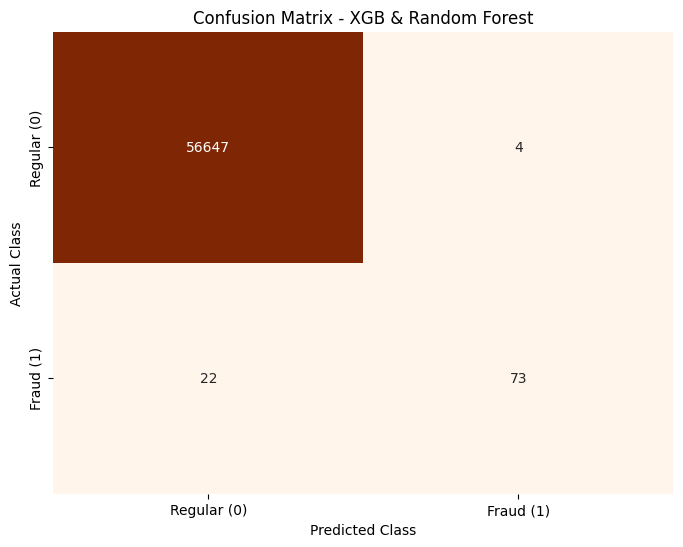

----------------------------------------
F1-Score: 0.8488
Recall: 0.7684
Precision: 0.9481
PR-AUC: 0.7289


In [27]:
proba_blended = (proba_xgb + proba_rf) / 2.0
y_pred_blended = (proba_blended >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred_blended)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['Regular (0)', 'Fraud (1)'], yticklabels=['Regular (0)', 'Fraud (1)'])
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.title('Confusion Matrix - XGB & Random Forest')
plt.show()
print(40*'-')
print(f"F1-Score: {f1_score(y_test, y_pred_blended):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_blended):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_blended):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_pred_blended):.4f}")

### Ensemble Performance & Strategic Roadmap
The initial symmetric blend of XGBoost and Random Forest achieved an F1-Score of 0.8488. While this is an incredibly strong result, it falls marginally short of the absolute peak set by the standalone XGBoost earlier (0.8538), having produced one additional False Positive.

However, a simple 50/50 average is rarely optimal. The slight drop in precision simply indicates that we need to calibrate the voting power of each model.

**Next Steps & Optimization Roadmap:**
Further optimization will be split into dedicated modeling notebooks to keep the workflow modular and clean.

1. **XGBoost Optimization Notebook:**
   * Hyperparameter fine-tuning utilizing the `Optuna` framework.
   * Probability Threshold calibration (Threshold Moving) to maximize precision.
   * Model explainability via SHAP (TreeExplainer) to interpret decision logic.

2. **Ensemble & Stacking Notebook:**
   * Re-evaluating the Stack with the newly optimized XGBoost parameters.
   * Implementing **Asymmetric Blending** (custom probability weighting) to allow the more confident model to lead the decision.
   * Calculating an optimal custom threshold for the blended probabilities.
   * Global explainability analysis using SHAP (KernelExplainer) for the entire hybrid architecture.